# Global World Bank & Cyber Incident Rate Spearman Analysis (2014–2024)

Cross-country panel analysis integrating **World Bank WDI** macroeconomic/digital indicators (including **New business density**, `IC.BUS.NDNS.ZS`) with **UMD Cyber Events** normalized as the primary incident rate (**incidents per 100,000 residents**, using World Bank `SP.POP.TOTL`).

- **Unit of observation:** Sovereign country × year (`country_iso3 × year`).
- **Correlation window:** `2014–2024` (year `2025` is excluded from cross-indicator heatmaps because World Bank `IC.BUS.NDNS.ZS` and `IT.NET.BBND.P2` have `0` reported countries in 2025, and `IT.NET.USER.ZS` has only `10`).


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

PROJECT_ROOT = Path(r"d:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany")
if str(PROJECT_ROOT / "scripts") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "scripts"))

PANEL_PATH = PROJECT_ROOT / "data" / "prepared" / "global_country_year_wb_umd.csv"
WB_RAW_PATH = PROJECT_ROOT / "data" / "raw" / "world_bank_global_2014_2025.csv"

if not PANEL_PATH.exists() or not WB_RAW_PATH.exists():
    from build_global_wb_panel import build_global_datasets
    build_global_datasets()

panel_all = pd.read_csv(PANEL_PATH)
wb_raw = pd.read_csv(WB_RAW_PATH)

# Use 2014-2024 where all 9 WB features have strong cross-country coverage
panel = panel_all[panel_all["year"].between(2014, 2024)].copy()
panel_1m = panel[panel["population"] >= 1_000_000].copy()

FEATURE_LABELS = {
    "gdp_per_capita_usd": "GDP per capita",
    "gdp_growth_pct": "GDP growth",
    "industry_gdp_pct": "Industry (% GDP)",
    "services_gdp_pct": "Services (% GDP)",
    "unemployment_rate_pct": "Unemployment rate",
    "labor_participation_pct": "Labor participation",
    "new_business_density": "New business density",
    "internet_users_pct": "Internet users (%)",
    "broadband_per_100": "Broadband per 100",
}
ALL_MATRIX_LABELS = {**FEATURE_LABELS, "incidents_per_100k": "Incidents per 100k"}

print(
    f"2014-2024 panel: {len(panel):,} rows across {panel['country_iso3'].nunique()} sovereign countries | "
    f"Matched UMD incidents: {int(panel['incident_count'].sum()):,}"
)
print(
    f"Population >= 1M subset: {len(panel_1m):,} rows across {panel_1m['country_iso3'].nunique()} countries | "
    f"Matched UMD incidents: {int(panel_1m['incident_count'].sum()):,}"
)


2014-2024 panel: 2,387 rows across 217 sovereign countries | Matched UMD incidents: 14,276
Population >= 1M subset: 1,760 rows across 160 countries | Matched UMD incidents: 14,197


## 1. Economic Indicators and Cyber Incident Rates — Pooled Spearman Matrix (2014–2024)

Full pairwise Spearman rank correlation matrix across all country-year observations (`2014–2024`)

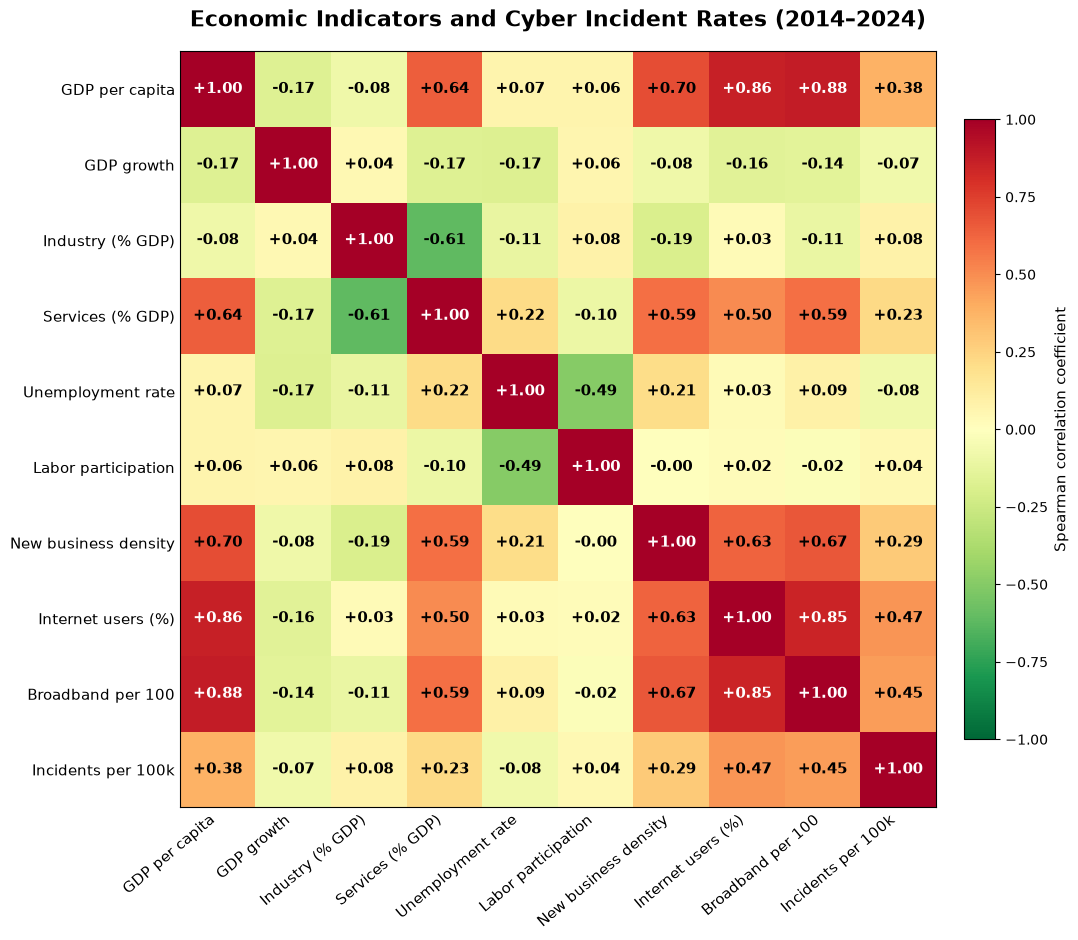

,All sovereign countries,Countries pop >= 1M
Internet users (%),0.472,0.577
Broadband per 100,0.452,0.599
GDP per capita,0.382,0.595
New business density,0.287,0.389
Services (% GDP),0.225,0.446
Industry (% GDP),0.084,-0.058
Labor participation,0.041,0.031
GDP growth,-0.072,-0.134
Unemployment rate,-0.078,-0.053


In [2]:
cols = list(ALL_MATRIX_LABELS.keys())
corr_matrix = (
    panel[cols]
    .corr(method="spearman")
    .rename(index=ALL_MATRIX_LABELS, columns=ALL_MATRIX_LABELS)
)

fig, ax = plt.subplots(figsize=(11.5, 9.5))
cmap = plt.get_cmap("RdYlGn_r").copy()
im = ax.imshow(corr_matrix.values, cmap=cmap, vmin=-1, vmax=1)

ax.set_xticks(range(len(corr_matrix.columns)))
ax.set_xticklabels(corr_matrix.columns, rotation=40, ha="right", fontsize=11)
ax.set_yticks(range(len(corr_matrix.index)))
ax.set_yticklabels(corr_matrix.index, fontsize=11)

for i in range(len(corr_matrix)):
    for j in range(len(corr_matrix)):
        val = corr_matrix.iloc[i, j]
        ax.text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=10.5,
            fontweight="bold",
            color="white" if abs(val) >= 0.70 else "black",
        )

ax.set_title(
    "Economic Indicators and Cyber Incident Rates (2014–2024)",
    fontsize=16,
    fontweight="bold",
    pad=18,
)
cbar = fig.colorbar(im, ax=ax, shrink=0.82, pad=0.03)
cbar.set_label("Spearman correlation coefficient", fontsize=11)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()

# Print sensitivity comparison: all 217 countries vs population >= 1M
corr_1m_target = (
    panel_1m[cols]
    .corr(method="spearman")["incidents_per_100k"]
    .drop("incidents_per_100k")
)
comp = pd.DataFrame({
    "All sovereign countries": corr_matrix.loc[list(FEATURE_LABELS.values()), "Incidents per 100k"],
    "Countries pop >= 1M": corr_1m_target.rename(index=FEATURE_LABELS),
}).round(3)
display(comp.sort_values("All sovereign countries", ascending=False))


## 2. Annual Economic Correlations with Cyber Incident Rates (2014–2024)

Each row computes cross-country Spearman rank correlations against `Incidents per 100k` within that individual year (`2014` through `2024`), testing whether associations persist over time or shift across periods.


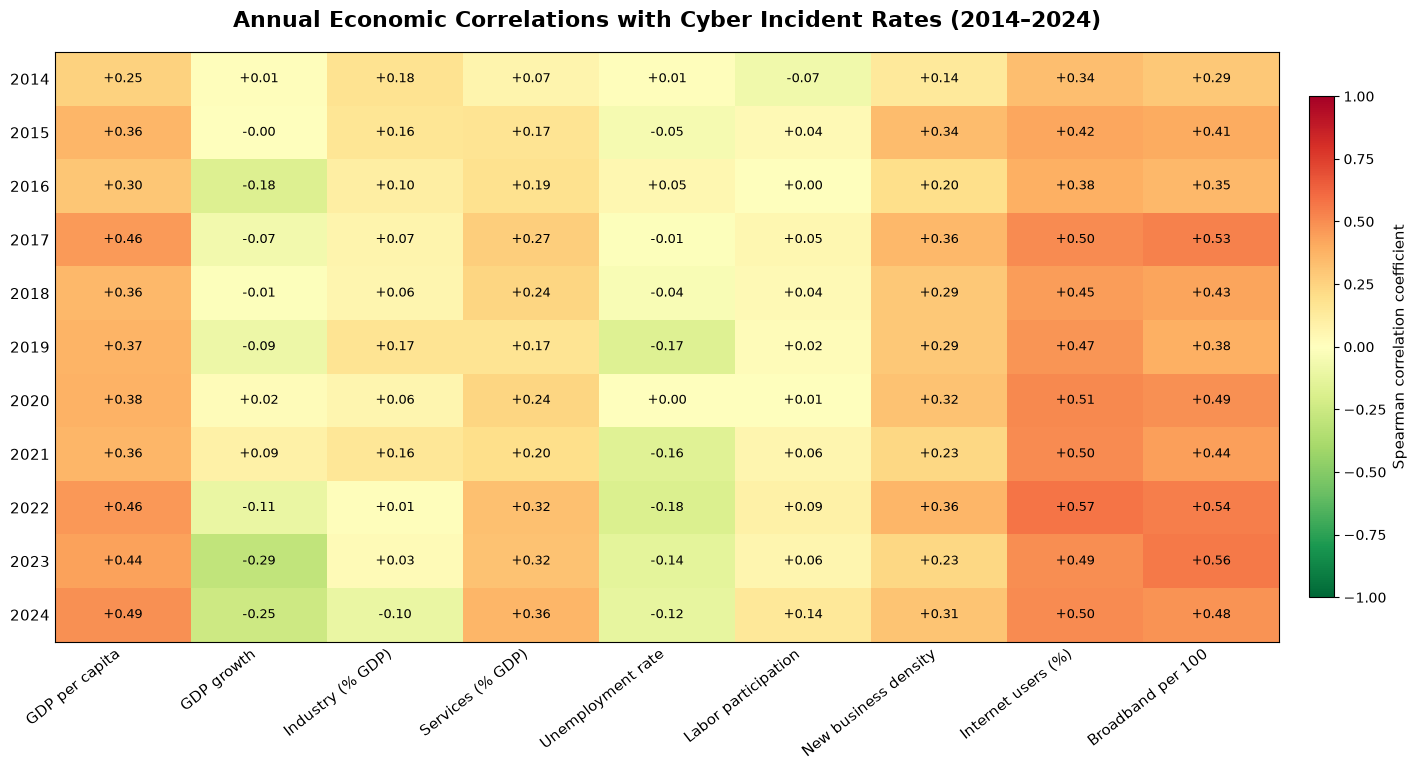

In [3]:
annual_rows = []
for yr, grp in panel.groupby("year"):
    c = grp[list(FEATURE_LABELS.keys()) + ["incidents_per_100k"]].corr(method="spearman")[
        "incidents_per_100k"
    ]
    annual_rows.append({"year": int(yr), **{lbl: c[col] for col, lbl in FEATURE_LABELS.items()}})

annual_df = pd.DataFrame(annual_rows).set_index("year")

fig, ax = plt.subplots(figsize=(15.5, 7.8))
im = ax.imshow(
    annual_df.values,
    cmap="RdYlGn_r",
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
    aspect="auto",
)

ax.set_xticks(range(len(annual_df.columns)))
ax.set_xticklabels(annual_df.columns, rotation=38, ha="right", fontsize=11)
ax.set_yticks(range(len(annual_df.index)))
ax.set_yticklabels(annual_df.index, fontsize=11)

for i in range(len(annual_df.index)):
    for j in range(len(annual_df.columns)):
        val = annual_df.iloc[i, j]
        ax.text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=9.5,
            color="white" if abs(val) >= 0.70 else "black",
        )

ax.set_title(
    "Annual Economic Correlations with Cyber Incident Rates (2014–2024)",
    fontsize=16,
    fontweight="bold",
    pad=18,
)
cbar = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
cbar.set_label("Spearman correlation coefficient", fontsize=11)
ax.tick_params(length=0)

plt.tight_layout()
plt.show()


## 3. Germany (`DEU`) vs. Global Sovereign Benchmark (2014–2024)

Side-by-side view of how **Germany** (`DEU`) compares against the **World aggregate (`WLD` / country median)** on the primary UMD incident rate (`incidents_per_100k`) and **New business density** (`IC.BUS.NDNS.ZS`), plus where Germany sits relative to the Population ≥ 1M sensitivity check.


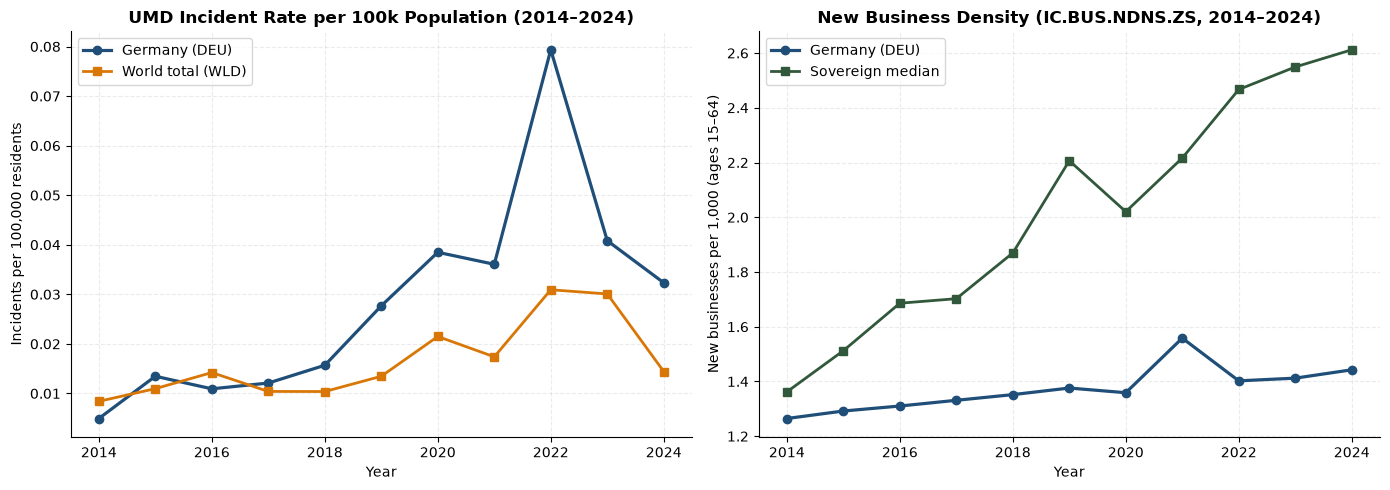

,year,incident_count,incidents_per_100k,gdp_per_capita_usd,new_business_density,internet_users_pct,broadband_per_100,wld_incidents_per_100k
600,2014,4,0.005,48959.599,1.265,86.194,36.341,0.008
601,2015,11,0.013,41929.755,1.292,87.590,37.413,0.011
602,2016,9,0.011,42948.938,1.310,84.165,38.499,0.014
603,2017,10,0.012,45553.934,1.331,84.394,39.989,0.010
604,2018,13,0.016,48916.169,1.352,87.037,40.965,0.010
605,2019,23,0.028,47656.200,1.376,88.135,42.116,0.013
606,2020,32,0.038,47394.873,1.359,89.813,43.305,0.021
607,2021,30,0.036,52349.246,1.558,91.431,44.064,0.017
608,2022,66,0.079,50506.518,1.402,91.630,44.619,0.031
609,2023,34,0.041,54776.767,1.412,92.476,45.381,0.030


In [4]:
deu = panel[panel["country_iso3"] == "DEU"].sort_values("year")
wld_pop = wb_raw[(wb_raw["country_iso3"] == "WLD") & (wb_raw["year"].between(2014, 2024))].sort_values("year")
global_inc = panel.groupby("year", as_index=False)["incident_count"].sum().merge(
    wld_pop[["year", "population", "new_business_density"]], on="year", how="left"
)
global_inc["wld_incidents_per_100k"] = global_inc["incident_count"] / global_inc["population"] * 100_000
med_nbd = panel.groupby("year")["new_business_density"].median().reset_index(name="median_nbd")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Incident rate DEU vs World aggregate (UMD)
axes[0].plot(deu["year"], deu["incidents_per_100k"], marker="o", linewidth=2.3, color="#1F4E78", label="Germany (DEU)")
axes[0].plot(global_inc["year"], global_inc["wld_incidents_per_100k"], marker="s", linewidth=2.0, color="#D97706", label="World total (WLD)")
axes[0].set_title("UMD Incident Rate per 100k Population (2014–2024)", fontweight="bold")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Incidents per 100,000 residents")
axes[0].set_xticks(range(2014, 2025, 2))
axes[0].grid(alpha=0.25, linestyle="--")
axes[0].spines[["top", "right"]].set_visible(False)
axes[0].legend()

# Right: New business density DEU vs World / Country Median
axes[1].plot(deu["year"], deu["new_business_density"], marker="o", linewidth=2.3, color="#1F4E78", label="Germany (DEU)")
axes[1].plot(med_nbd["year"], med_nbd["median_nbd"], marker="s", linewidth=2.0, color="#31583B", label="Sovereign median")
axes[1].set_title("New Business Density (IC.BUS.NDNS.ZS, 2014–2024)", fontweight="bold")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("New businesses per 1,000 (ages 15–64)")
axes[1].set_xticks(range(2014, 2025, 2))
axes[1].grid(alpha=0.25, linestyle="--")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend()

plt.tight_layout()
plt.show()

summary_deu = deu[["year", "incident_count", "incidents_per_100k", "gdp_per_capita_usd", "new_business_density", "internet_users_pct", "broadband_per_100"]].copy()
summary_deu["wld_incidents_per_100k"] = global_inc["wld_incidents_per_100k"].values
display(summary_deu.round(3))


## 4. Sensitivity Check — Germany Only: `UMD` vs. Combined DE Dataset (2,323 Incidents)

In Sections 1–2, Spearman correlations measure **cross-country differences** across `217` sovereign countries. Here we isolate **Germany (`DEU`) alone across `n = 11` years (`2014–2024`)** and test how much the correlation changes when replacing Germany's single global source (`UMD`: `259` incidents in 2014–2024) with the full deduplicated German dataset ([germany_large_incidents.csv]): `2,323` incidents total, `1,324` in 2014–2024).

### What happens and why it must be interpreted carefully
1. **Correlations jump sharply with the combined DE dataset** (e.g., `Broadband per 100` rises from `+0.86` to **`+0.97`**, `New business density` from `+0.80` to **`+0.91`**, and `GDP per capita` from `+0.55` to **`+0.72`**).
2. **Spurious time-trend effect (`n = 11` annual points):** Inside one country over just 11 consecutive years, structural indicators such as `Broadband per 100`, `Internet users (%)`, `New business density`, and `Services (% GDP)` trend monotonically upward. Any incident series that climbs year after year automatically gets `+0.89` to `+0.97` rank correlation—even without a causal link.
3. **The 2021 coverage break:** `UMD` in Germany peaks in `2022` (`66`) and drops in `2023–2024` (`34 → 27`). By contrast, the combined DE dataset jumps from `35` (`2020`) to `140` (`2021`), `272` (`2022`), `421` (`2023`), and `363` (`2024`), largely because **KonBriefing starts in 2021** (`0 → 102`) and **Ransomware.live** accelerates rapidly from 2022 onward—making the combined curve track upward-trending World Bank series even more tightly.
4. **Raw count vs. per-100k inside Germany:** Because Germany's population changes slowly relative to annual incident jumps, `combined_de_incidents` and `combined_de_per_100k` produce the **exact same** Spearman correlation.


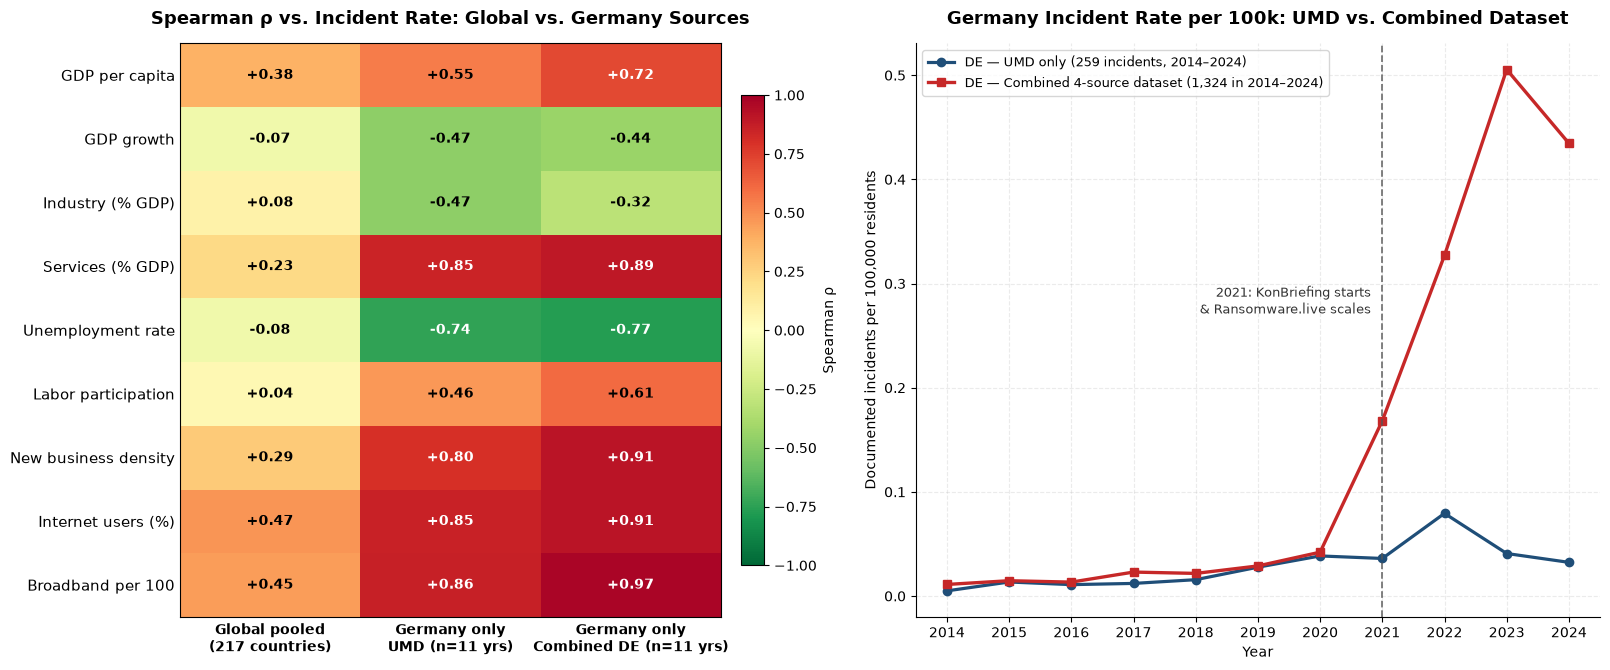

Full germany_large_incidents.csv rows: 2,323 | 2014-2024 subset: 1,324 vs UMD: 259


,Global pooled (n=217),DE UMD per 100k (n=11),DE Combined per 100k (n=11),Delta (DE Combined - DE UMD)
GDP per capita,0.382,0.555,0.718,0.164
GDP growth,-0.072,-0.473,-0.436,0.036
Industry (% GDP),0.084,-0.473,-0.318,0.155
Services (% GDP),0.225,0.845,0.891,0.045
Unemployment rate,-0.078,-0.736,-0.773,-0.036
Labor participation,0.041,0.464,0.609,0.145
New business density,0.287,0.800,0.909,0.109
Internet users (%),0.472,0.855,0.909,0.055
Broadband per 100,0.452,0.864,0.973,0.109


,year,de_umd_incidents,de_combined_incidents,de_umd_per_100k,de_combined_per_100k,new_business_density,broadband_per_100
0,2014,4,9,0.0049,0.0111,1.2648,36.3409
1,2015,11,12,0.0135,0.0147,1.2921,37.4127
2,2016,9,11,0.0109,0.0134,1.3104,38.4991
3,2017,10,19,0.0121,0.0230,1.3313,39.9888
4,2018,13,18,0.0157,0.0217,1.3520,40.9651
5,2019,23,24,0.0277,0.0289,1.3761,42.1156
6,2020,32,35,0.0385,0.0421,1.3590,43.3049
7,2021,30,140,0.0361,0.1683,1.5585,44.0643
8,2022,66,272,0.0793,0.3270,1.4024,44.6186
9,2023,34,421,0.0408,0.5055,1.4122,45.3805


In [5]:
DE_INC_PATH = PROJECT_ROOT / "data" / "prepared" / "germany_large_incidents.csv"
de_incidents_raw = pd.read_csv(DE_INC_PATH)

de_yearly_combined = (
    de_incidents_raw[de_incidents_raw["year"].between(2014, 2024)]
    .groupby("year", as_index=False)
    .size()
    .rename(columns={"size": "de_combined_incidents"})
)

deu_comp = (
    panel[panel["country_iso3"] == "DEU"]
    .sort_values("year")
    .merge(de_yearly_combined, on="year", how="left", validate="one_to_one")
)
deu_comp["de_combined_per_100k"] = (
    deu_comp["de_combined_incidents"] / deu_comp["population"] * 100_000
)

feat_cols = list(FEATURE_LABELS.keys())
feat_names = [FEATURE_LABELS[c] for c in feat_cols]

# 1) Global pooled cross-country (from Section 1)
rho_global = corr_matrix.loc[feat_names, "Incidents per 100k"].values

# 2) Germany only (n=11 yrs): UMD per 100k vs Combined DE dataset per 100k
de_corr = deu_comp[feat_cols + ["incidents_per_100k", "de_combined_per_100k"]].corr(
    method="spearman"
)
rho_de_umd = de_corr.loc[feat_cols, "incidents_per_100k"].values
rho_de_comb = de_corr.loc[feat_cols, "de_combined_per_100k"].values

comp_mat = pd.DataFrame(
    {
        "Global pooled\n(217 countries)": rho_global,
        "Germany only\nUMD (n=11 yrs)": rho_de_umd,
        "Germany only\nCombined DE (n=11 yrs)": rho_de_comb,
    },
    index=feat_names,
)

fig, axes = plt.subplots(
    1, 2, figsize=(16.2, 6.8), gridspec_kw={"width_ratios": [1.08, 1.12]}
)

# Left panel: 3-column Spearman comparison heatmap
im = axes[0].imshow(
    comp_mat.values,
    cmap="RdYlGn_r",
    norm=TwoSlopeNorm(vmin=-1, vcenter=0, vmax=1),
    aspect="auto",
)
axes[0].set_xticks(range(comp_mat.shape[1]))
axes[0].set_xticklabels(comp_mat.columns, fontsize=9.8, fontweight="bold")
axes[0].set_yticks(range(comp_mat.shape[0]))
axes[0].set_yticklabels(comp_mat.index, fontsize=10.5)
for i in range(comp_mat.shape[0]):
    for j in range(comp_mat.shape[1]):
        val = comp_mat.iloc[i, j]
        axes[0].text(
            j,
            i,
            f"{val:+.2f}",
            ha="center",
            va="center",
            fontsize=10,
            fontweight="bold",
            color="white" if abs(val) >= 0.70 else "black",
        )
axes[0].set_title(
    "Spearman ρ vs. Incident Rate: Global vs. Germany Sources",
    fontsize=13,
    fontweight="bold",
    pad=14,
)
axes[0].tick_params(length=0)
cbar = fig.colorbar(im, ax=axes[0], shrink=0.82, pad=0.03)
cbar.set_label("Spearman ρ", fontsize=10)

# Right panel: Why Germany correlations shift (trajectory comparison)
axes[1].plot(
    deu_comp["year"],
    deu_comp["incidents_per_100k"],
    marker="o",
    linewidth=2.3,
    color="#1F4E78",
    label="DE — UMD only (259 incidents, 2014–2024)",
)
axes[1].plot(
    deu_comp["year"],
    deu_comp["de_combined_per_100k"],
    marker="s",
    linewidth=2.4,
    color="#C62828",
    label="DE — Combined 4-source dataset (1,324 in 2014–2024)",
)
axes[1].axvline(2021, color="#555555", linestyle="--", linewidth=1.3, alpha=0.8)
axes[1].text(
    2020.82,
    deu_comp["de_combined_per_100k"].max() * 0.56,
    "2021: KonBriefing starts\n& Ransomware.live scales",
    fontsize=9.5,
    color="#333333",
    ha="right",
    va="center",
)
axes[1].set_title(
    "Germany Incident Rate per 100k: UMD vs. Combined Dataset",
    fontsize=13,
    fontweight="bold",
    pad=14,
)
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Documented incidents per 100,000 residents")
axes[1].set_xticks(range(2014, 2025))
axes[1].grid(alpha=0.25, linestyle="--")
axes[1].spines[["top", "right"]].set_visible(False)
axes[1].legend(loc="upper left", fontsize=9.5)

plt.tight_layout()
plt.show()

print(
    f"Full germany_large_incidents.csv rows: {len(de_incidents_raw):,} | "
    f"2014-2024 subset: {int(deu_comp['de_combined_incidents'].sum()):,} vs UMD: {int(deu_comp['incident_count'].sum()):,}"
)
delta_table = pd.DataFrame(
    {
        "Global pooled (n=217)": rho_global,
        "DE UMD per 100k (n=11)": rho_de_umd,
        "DE Combined per 100k (n=11)": rho_de_comb,
        "Delta (DE Combined - DE UMD)": rho_de_comb - rho_de_umd,
    },
    index=feat_names,
).round(3)
display(delta_table)

display(
    deu_comp[
        [
            "year",
            "incident_count",
            "de_combined_incidents",
            "incidents_per_100k",
            "de_combined_per_100k",
            "new_business_density",
            "broadband_per_100",
        ]
    ]
    .rename(columns={"incident_count": "de_umd_incidents", "incidents_per_100k": "de_umd_per_100k"})
    .round(4)
)

